In [1]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns
from matplotlib.lines import Line2D

In [2]:
# Load the data
df = pd.read_csv('../csv/player_valuations.csv')

# Set the player_id ad index of the DataFrame
df.set_index('player_id')

,last_season,datetime,date,dateweek,market_value_in_eur,n,current_club_id,player_club_domestic_competition_id
player_id,,,,,,,,
3132,2013,2003-12-09 00:00:00,2003-12-09,2003-12-08,400000,1,126,TR1
6893,2012,2003-12-15 00:00:00,2003-12-15,2003-12-15,900000,1,984,GB1
10,2015,2004-10-04 00:00:00,2004-10-04,2004-10-04,7000000,1,398,IT1
26,2017,2004-10-04 00:00:00,2004-10-04,2004-10-04,1500000,1,16,L1
65,2015,2004-10-04 00:00:00,2004-10-04,2004-10-04,8000000,1,1091,GR1
...,...,...,...,...,...,...,...,...
950091,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,1000000,1,1091,GR1
968903,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,50000,1,653,GR1
1031590,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,50000,1,6418,GR1


# Data Exploration
The dataset contains 8 columns and 440663, each providing distinct information about football players and their career statistics. Below is a description of the key columns relevant for the analysis:

- `player_id`: Unique identifier for each player.
- `last_season`: The last season in which the player participated.
- `datetime`: Date and time in which has been done the valuation of each player
- `date`: Date in which has been done the valuation of each player
- `dateweek`: Week-based date representation used for time-series or weekly data analysis.
- `market_value_in_eur`: The current market value of the player in euros.
- `n`: Numerical variable, which seems to be unimportant
- `current_club_id`: Identifier for the player's current club.
- `player_club_domestic_competition_id`: Identifier for the domestic competition in which the player's current club is participating.

This data allows for detailed exploration of player statistics, career history, and market trends.


In [3]:
#watch out if there are missing values
missing_data = df.isnull().mean()

missing_data

player_id                              0.0
last_season                            0.0
datetime                               0.0
date                                   0.0
dateweek                               0.0
market_value_in_eur                    0.0
n                                      0.0
current_club_id                        0.0
player_club_domestic_competition_id    0.0
dtype: float64

## Data Cleaning

In [4]:
# Convert 'datetime' column to datetime type
df['datetime'] = pd.to_datetime(df['datetime'])

# Extract the time part
df['time'] = df['datetime'].dt.time

# Check if all time values are the same
all_same = df['time'].nunique() == 1
if all_same:
    df.drop(columns=['datetime', 'time'], inplace=True)
df.drop(columns=['n', 'dateweek'], inplace=True)
df['date'] = pd.to_datetime(df['date'])
df

,player_id,last_season,date,market_value_in_eur,current_club_id,player_club_domestic_competition_id
0,3132,2013,2003-12-09,400000,126,TR1
1,6893,2012,2003-12-15,900000,984,GB1
2,10,2015,2004-10-04,7000000,398,IT1
3,26,2017,2004-10-04,1500000,16,L1
4,65,2015,2004-10-04,8000000,1091,GR1
...,...,...,...,...,...,...
440658,950091,2023,2023-09-21,1000000,1091,GR1
440659,968903,2023,2023-09-21,50000,653,GR1
440660,1031590,2023,2023-09-21,50000,6418,GR1
440661,1166093,2023,2023-09-21,50000,30120,GR1


# Time Consistency Check in Datetime Column

In this section, we check the consistency of the time component in the `datetime` column of the DataFrame. The following steps are performed:

   - We extract the time part from the `datetime` column, creating a new column named `time`, so that we can check if the column `datetime` is useful

   - We verify if all extracted time values are the same using the `nunique()` method. If they are identical, we proceed to drop the `datetime` and `time` columns from the DataFrame.

   - We also drop the columns `n` and `dateweek` from the DataFrame as they are no longer needed.

### Result:
The DataFrame is updated by removing the `datetime`, `time`, `n`, and `dateweek` columns if the time component was consistent across all entries. This helps in streamlining the data for further analysis.


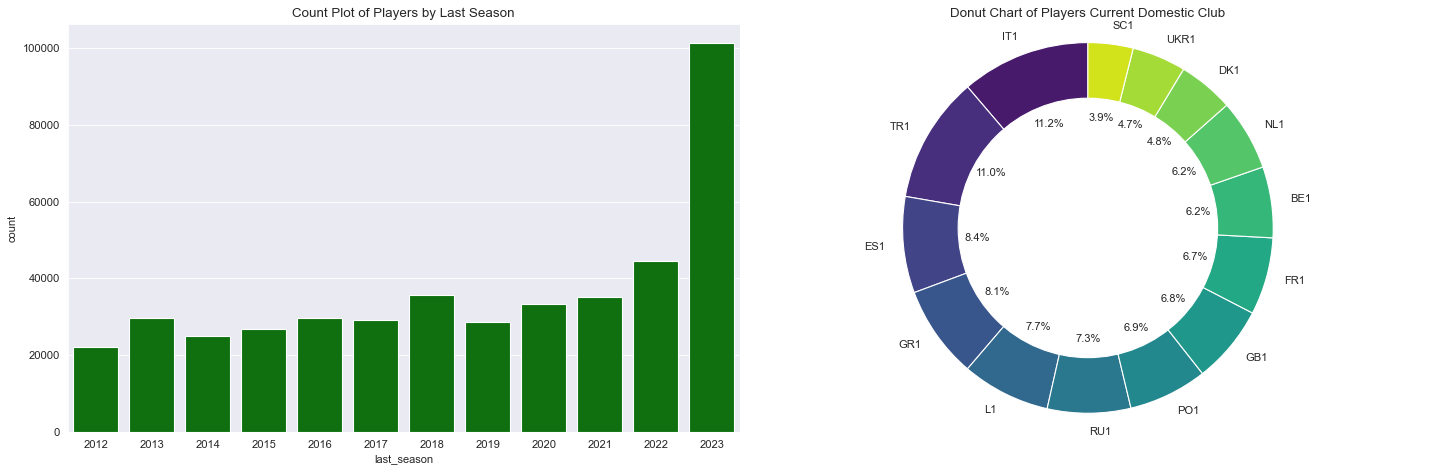

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6), dpi=80)

# Display the counts of observations for each season
sns.countplot(data=df, x='last_season', ax=axs[0], color= 'green')
axs[0].set_title('Count Plot of Players by Last Season')

unique_clubs = df['player_club_domestic_competition_id'].nunique()

# Select clubs with the highest number of players
top_clubs = df['player_club_domestic_competition_id'].value_counts().head(unique_clubs).index

# Filter the DataFrame to include only the top clubs
df_top_clubs = df[df['player_club_domestic_competition_id'].isin(top_clubs)]

# Count the players for the top clubs
top_club_counts = df_top_clubs['player_club_domestic_competition_id'].value_counts()

# Create a donut chart for the top clubs
axs[1].pie(top_club_counts, labels=top_club_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette('viridis', len(top_club_counts)))

# Draw a circle at the center of pie to make it look like a donut
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Equal aspect ratio ensures that pie is drawn as a circle
axs[1].axis('equal')  
axs[1].set_title('Donut Chart of Players Current Domestic Club')

plt.tight_layout()
plt.show()


# Count Plots of Players by Last Season and Top 10 Current Clubs

This visualization contains two count plots side by side:

1. **Count Plot of Players by Last Season**:
   - Displays the number of players based on their last active season.
   - Provides an overview of the distribution of players who participated in different seasons. 

   ### Observation:
   - The last season '2023' has the most element in it, and it's the most recent season in the dataset.

   <br>
2. **Donut chart of Players by Current Clubs**:
   - Focuses on the top 10 clubs with the highest number of players, showing the distribution of players across these clubs.
   - Only includes clubs with the most players, making it easier to identify which clubs have a significant representation in the dataset.

The visualizations are useful for understanding the distribution of player participation across seasons and clubs, offering insights into team sizes and player turnover over time.


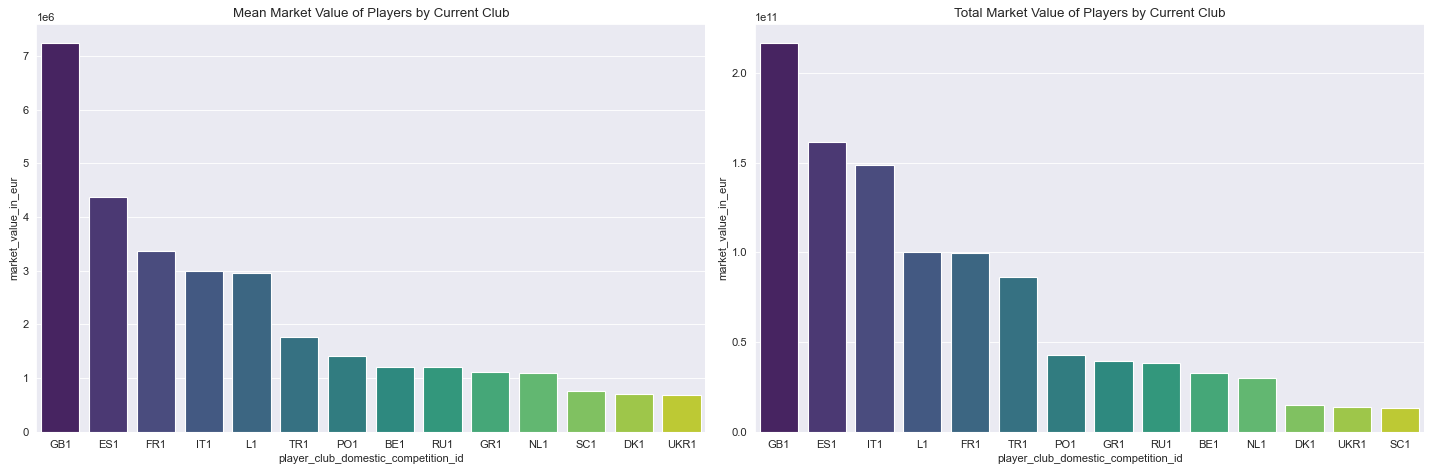

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(18, 6), dpi=80)

# Calculate the mean market value of players by current club
mean_market_value_clubs = df.groupby(['player_club_domestic_competition_id']).agg({'market_value_in_eur': 'mean'}).sort_values(by='market_value_in_eur', ascending=False)

# Bar plot for mean market value
sns.barplot(data=mean_market_value_clubs.reset_index(), x='player_club_domestic_competition_id', y='market_value_in_eur', hue='player_club_domestic_competition_id' ,ax=axs[0], palette='viridis')
axs[0].set_title('Mean Market Value of Players by Current Club')  

# Calculate the total market value of players by current club
market_value_clubs = df.groupby(['player_club_domestic_competition_id']).agg({'market_value_in_eur': 'sum'}).sort_values(by='market_value_in_eur', ascending=False)

# Bar plot for total market value
sns.barplot(data=market_value_clubs.reset_index(), x='player_club_domestic_competition_id', y='market_value_in_eur', hue='player_club_domestic_competition_id' ,ax=axs[1], palette='viridis')
axs[1].set_title('Total Market Value of Players by Current Club') 

plt.tight_layout()  # Adjust layout to prevent overlap
plt.show()


# Market Value of Players by Current Club

These visualizations are performed with the `market_value_in_eur` provided by the `data` column.

The figures above display two bar charts that compare the market values of players by their current clubs:

1. **Mean Market Value of Players by Current Club (Left Chart)**:
   - This chart represents the average market value of players across different clubs.
   - The club with the highest mean market value is **GB1**, followed by **ES1** and **FR1**.
   - It highlights which clubs have a higher average player value, indicating stronger talent within those teams.

2. **Total Market Value of Players by Current Club (Right Chart)**:
   - This chart shows the total market value of all players associated with each club.
   - Again, **GB1** leads the chart, indicating a significant total investment in players.
   - The total market value offers insights into the financial power of clubs based on the combined value of their player rosters.

These visualizations are crucial for understanding the economic landscape of football clubs, illustrating not only the average worth of talent but also the total investment in players by each club.


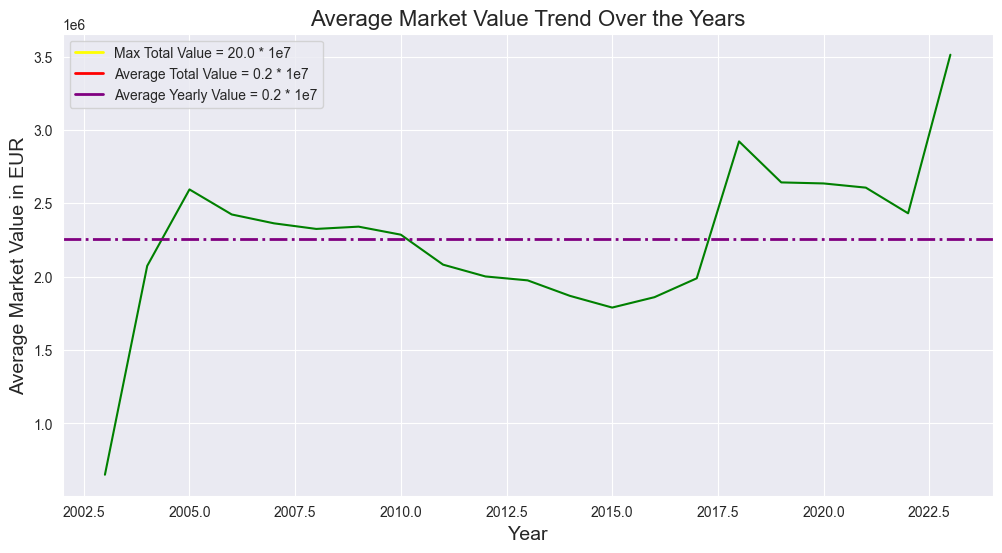

In [7]:
df['date'] = pd.to_datetime(df['date'])

# Extract year from the date
df['year'] = df['date'].dt.year

# Group by year and calculate the average market value
average_market_value_per_year = df.groupby('year')['market_value_in_eur'].mean().reset_index()

# Get the maximum average market value
max_value = df['market_value_in_eur'].max()
average_value = df['market_value_in_eur'].mean()

# Calculate the mean of the average market value over the years
mean_yearly_value = average_market_value_per_year['market_value_in_eur'].mean()

# Create a line chart for average market value over the years
plt.figure(figsize=(12, 6))
sns.lineplot(x='year', y='market_value_in_eur', data=average_market_value_per_year, color='green')

# Set the title and labels
plt.title('Average Market Value Trend Over the Years', fontsize=16)
plt.xlabel('Year', fontsize=14)
plt.ylabel('Average Market Value in EUR', fontsize=14)

# Customize legend entries
custom_legend_entry_max = Line2D(
    [0], [0], 
    color='yellow', 
    lw=2, 
    label=f'Max Total Value = {max_value / (10**7):.1f} * 1e7')
custom_legend_entry_avg = Line2D(
    [0], [0], 
    color='red', 
    lw=2, 
    label=f'Average Total Value = {average_value / (10**7):.1f} * 1e7')
custom_legend_entry_avg_year = Line2D(
    [0], [0], 
    color='purple', 
    lw=2, 
    label=f'Average Yearly Value = {mean_yearly_value / (10**7):.1f} * 1e7'
)

plt.axhline(y=mean_yearly_value, color='purple', linestyle='-.', label=f'Mean Yearly Value', linewidth=2)

plt.legend(handles=[custom_legend_entry_max, custom_legend_entry_avg, custom_legend_entry_avg_year])

plt.grid(True)

# Show the plot
plt.show()

# Average Market Value Trend Over the Years

The chart above illustrates the **average market value** of players over the years, showcasing how player values have evolved in the football landscape. 

### Key Insights:

1. **Trend Analysis**:
   - The line chart displays the average market value in euros, providing insights into fluctuations and trends in player valuation over time.
   - Any noticeable peaks or declines can indicate significant changes in the football market, such as transfer surges, economic impacts, or shifts in player performance.

2. **Max and Average Values**:
   - The **maximum total value** of players is represented in **yellow**, highlighting the highest market value recorded in the dataset.
   - The **average total value** of all players across the entire dataset is shown in **red**, indicating the general market trend.

3. **Mean Yearly Value**:
   - The **mean yearly value** of players is represented by a **purple dashed line**, providing a benchmark against which yearly averages can be compared. This allows for an easy assessment of whether the average market value in any given year was above or below the overall trend.

### Conclusion:
This visualization is essential for understanding the economic dynamics of player valuations in football, offering a clear picture of how market values are changing year by year and what factors may be influencing these trends.


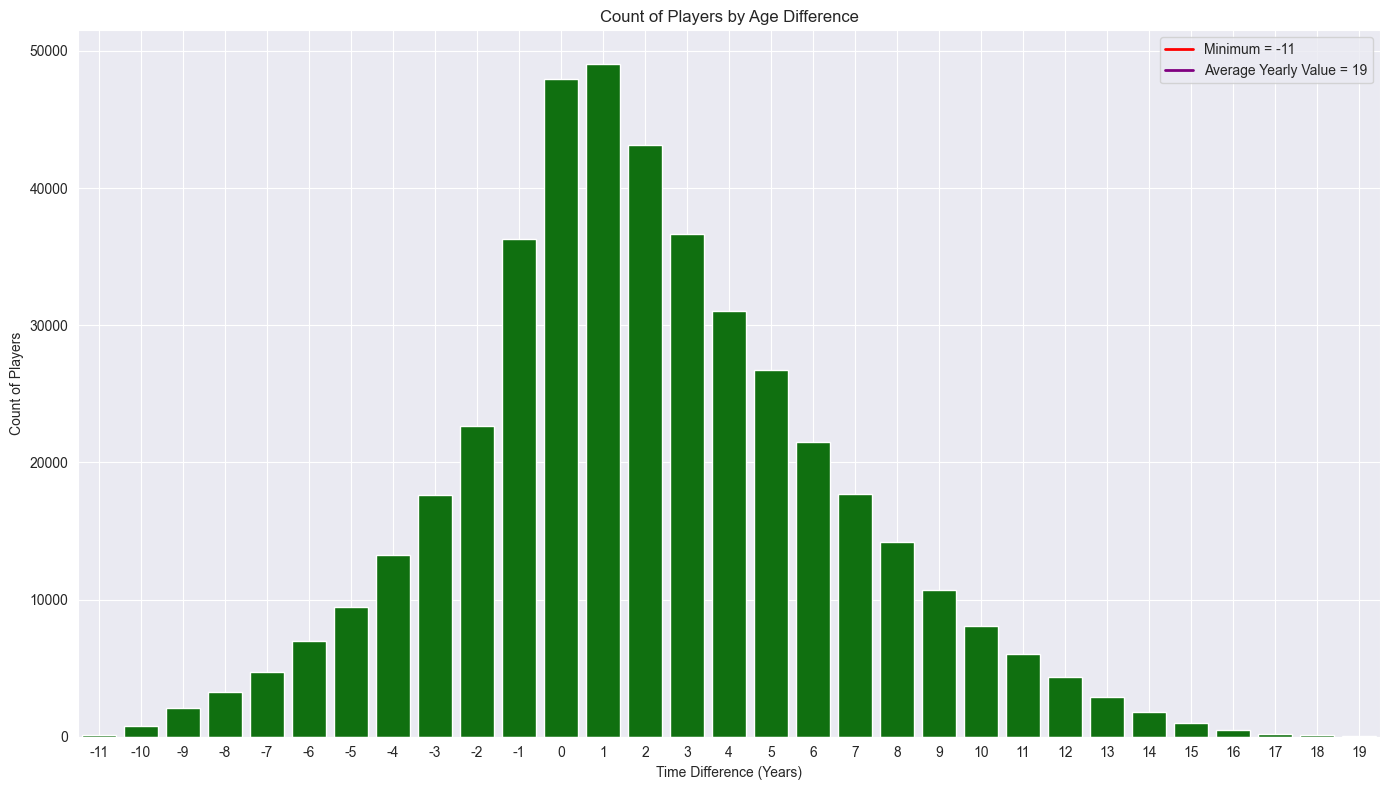

In [8]:
# Convert 'date' to datetime
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d')

# Convert 'last_season' to datetime using only the year
df['last_season'] = pd.to_datetime(df['last_season'], format='%Y')

# Calculate time difference
tempo = df['last_season'].dt.year - df['date'].dt.year
df['time_difference'] = tempo

# Calculate the count of players for each age difference
count_per_difference = df['time_difference'].value_counts().sort_index()

# Get minimum and maximum time differences
minimo = count_per_difference.index.min()
massimo = count_per_difference.index.max()

# Filter DataFrame for players with min and max time difference
min_players = df[df['time_difference'] == minimo]
max_players = df[df['time_difference'] == massimo]

minimo = Line2D(
    [0], [0], 
    color='red', 
    lw=2, 
    label=f'Minimum = {minimo}')
massimo = Line2D(
    [0], [0], 
    color='purple', 
    lw=2, 
    label=f'Average Yearly Value = {massimo}')
# Create a figure for the plots
plt.figure(figsize=(14, 8))

# Plotting the count of players for each age difference
sns.barplot(x=count_per_difference.index, y=count_per_difference.values, color='green')
plt.title('Count of Players by Age Difference')
plt.xlabel('Time Difference (Years)')
plt.ylabel('Count of Players')
plt.legend(handles=[minimo, massimo])
plt.grid(True)

# Adjust layout
plt.tight_layout()
plt.show()

df.drop(columns=['time_difference', 'year'], inplace=True)

# Analysis of the valuation and last season of the players

## Overview

This analysis focuses on the age differences between players based on their evaluation dates and the last season. 

   - The `date` column, representing the player's evaluation date, was converted to datetime format.
   - The `last_season` column was similarly converted, using only the year for calculation.
   - A bar chart was generated to display the count of players by their age differences.

## Results

The bar chart illustrates the count of players distributed by age difference (in years) between their evaluation date and the last season they played. 

### Interpretation
- The x-axis represents the time difference in years, which indicates how long it has been since the player's last season compared to their evaluation date.
- The y-axis represents the count of players for each age difference.

## Conclusion

This analysis reveals how players are distributed across different time differences from their evaluation date to the last season. 

In [9]:
df.to_csv('../cleaned_csv/player_valuations_cleaned.csv', index=False)